# 유클리드 거리 vs DTW vs 대역 제한 DTW — 보고서 시각화(그림) 모음


In [1]:
!pip install -q koreanize-matplotlib

### [0] 환경 설정

In [2]:
import os, sys, time, random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.ticker import FuncFormatter
import seaborn as sns
try:
    import koreanize_matplotlib  # noqa: F401
except ImportError:
    pass
plt.rcParams["font.family"] = ["NanumGothic", "DejaVu Sans"]   # 한글 폰트에 없는 기호(−, √ 등)는 DejaVu Sans로 표시
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
os.makedirs("figs", exist_ok=True)
INF = float("inf")

COL_A, COL_B, COL_C = "#2a78d6", "#eb6834", "#1baf7a"     # A=파랑, B=주황, C=청록
COL_HL, COL_NB, COL_GRID, COL_TXT2 = "#e34948", "#eda100", "#d9d8d4", "#52514e"


def save(fig, name):
    fig.savefig(f"figs/{name}.png", dpi=200, bbox_inches="tight", facecolor="white")
    if "google.colab" in sys.modules or "ipykernel" in sys.modules:
        plt.show()
    plt.close(fig)
    print("saved:", name)

### [1] 핵심 알고리즘

In [3]:
def euclidean(a, b, trace=False):
    """선형 탐색: i번째 원소끼리만 1:1 비교 → O(n) 시간, O(1) 공간"""
    assert len(a) == len(b)
    s, steps = 0, []
    for i in range(len(a)):
        d = (a[i] - b[i]) ** 2        # 같은 시점끼리 차이의 제곱
        s += d                        # 누적합
        steps.append((i, d, s))
    return (s ** 0.5, steps) if trace else s ** 0.5


def dtw_table(a, b, r=None):
    """DTW 누적 비용 테이블 D (DP).
    r=None: 제약 없는 DTW, O(nm) / r=정수: 사코-치바 밴드 |i-j|<=r 칸만 계산, O(n·r)"""
    n, m = len(a), len(b)
    D = np.full((n + 1, m + 1), INF)
    D[0, 0] = 0.0
    order = []
    for i in range(1, n + 1):
        lo, hi = (1, m) if r is None else (max(1, i - r), min(m, i + r))
        for j in range(lo, hi + 1):
            cost = (a[i - 1] - b[j - 1]) ** 2                 # 지역 비용
            D[i, j] = cost + min(D[i - 1, j - 1],            # ↖ 둘 다 다음 점으로
                                 D[i - 1, j],                # ↑ A만 다음 점으로
                                 D[i, j - 1])                # ← B만 다음 점으로
            order.append((i, j))
    return D, order


def dtw(a, b, r=None):
    return dtw_table(a, b, r)[0][-1, -1] ** 0.5


def backtrack(D):
    """(n,m)에서 (1,1)까지 ↖ ↑ ← 중 누적 비용이 가장 작은 칸으로 거꾸로 이동"""
    i, j = D.shape[0] - 1, D.shape[1] - 1
    path = [(i, j)]
    while (i, j) != (1, 1):
        cands = [(D[i - 1, j - 1], i - 1, j - 1), (D[i - 1, j], i - 1, j), (D[i, j - 1], i, j - 1)]
        _, i, j = min(cands, key=lambda t: t[0])
        path.append((i, j))
    return path[::-1]          # 1-based (i, j)

### [2] 입력 데이터 (원소 9개)

In [4]:
A = [1, 2, 5, 6, 4, 2, 1, 0, 0]     # 기준 동작
B = [0, 0, 1, 2, 5, 6, 4, 2, 1]     # 같은 동작, 2프레임 늦게 시작
C = [1, 2, 3, 3, 3, 2, 1, 0, 0]     # 시작 시점은 같지만 덜 굽힌 '다른' 동작
N = len(A)

D_AB, ORDER_AB = dtw_table(A, B)
PATH_AB = backtrack(D_AB)
eAB, eAC = euclidean(A, B), euclidean(A, C)
dAB, dAC = dtw(A, B), dtw(A, C)
print(f"Euclid(A,B)={eAB:.2f}  Euclid(A,C)={eAC:.2f}  DTW(A,B)={dAB:.2f}  DTW(A,C)={dAC:.2f}")
print("워핑 경로(1-based):", PATH_AB)

Euclid(A,B)=8.25  Euclid(A,C)=3.74  DTW(A,B)=2.00  DTW(A,C)=3.74
워핑 경로(1-based): [(1, 1), (1, 2), (1, 3), (2, 4), (3, 5), (4, 6), (5, 7), (6, 8), (7, 9), (8, 9), (9, 9)]


### [3] 그리기 도우미 (여러 그림에서 함께 쓰는 함수)

In [5]:
def plot_pair(ax, a, b, pairs, title="", gap=8, hl=None, style="--"):
    x = np.arange(len(a))
    ax.plot(x, np.array(a), "-o", color=COL_A, lw=2, ms=7, label="A (기준 동작)", zorder=3)
    ax.plot(x, np.array(b) - gap, "-o", color=COL_B, lw=2, ms=7, label="B (2프레임 늦게 시작한 같은 동작)", zorder=3)
    for k, (i, j) in enumerate(pairs):
        on = hl is not None and k == hl
        ax.plot([i, j], [a[i], b[j] - gap], style, color=COL_HL if on else "#8f8e89",
                lw=2.4 if on else 1.2, zorder=2)
    ax.set_title(title, fontsize=12)
    ax.set_xticks(x); ax.set_xticklabels([str(t + 1) for t in x])
    ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_xlabel("시간(프레임)")


def draw_table(ax, a, b, D, filled, cur=None, path=None, band=None, title="", vmax=None, numbers=None):
    n, m = len(a), len(b)
    finite = D[np.isfinite(D)]
    vmax = vmax or finite.max()
    cmap = plt.get_cmap("Blues")
    for i in range(n + 1):
        for j in range(m + 1):
            if band is not None and i > 0 and j > 0 and abs(i - j) > band:
                face, txt, tc = "#e6e5e1", "", COL_TXT2
            elif i == 0 or j == 0:
                face, txt, tc = "#f5f4f1", ("0" if i == j == 0 else "∞"), COL_TXT2
            elif (i, j) in filled:
                v = D[i, j]
                face = cmap(0.08 + 0.75 * min(v, vmax) / vmax)
                txt, tc = f"{int(v)}", ("white" if v / vmax > 0.5 else "#0b0b0b")
            else:
                face, txt, tc = "white", "", "#0b0b0b"
            ax.add_patch(patches.Rectangle((j, i), 1, 1, facecolor=face, edgecolor=COL_GRID, lw=1))
            if txt:
                ax.text(j + 0.5, i + 0.5, txt, ha="center", va="center", fontsize=8.5, color=tc)
    if path:
        for k, (i, j) in enumerate(path):
            ax.add_patch(patches.Rectangle((j, i), 1, 1, fill=False, edgecolor=COL_HL, lw=2.6))
            if numbers:
                ax.text(j + 0.88, i + 0.2, str(numbers[k]), ha="center", va="center", fontsize=7,
                        color="white", bbox=dict(boxstyle="circle,pad=0.15", fc=COL_HL, ec="none"))
    if cur:
        i, j = cur
        ax.add_patch(patches.Rectangle((j, i), 1, 1, fill=False, edgecolor=COL_HL, lw=3.4))
        for (pi, pj) in [(i - 1, j - 1), (i - 1, j), (i, j - 1)]:
            ax.add_patch(patches.Rectangle((pj, pi), 1, 1, fill=False, edgecolor=COL_NB, lw=2.8))
            ax.annotate("", xy=(j + 0.5, i + 0.5), xytext=(pj + 0.5, pi + 0.5),
                        arrowprops=dict(arrowstyle="->", color=COL_NB, lw=2, shrinkA=7, shrinkB=13))
    ax.set_xlim(0, m + 1); ax.set_ylim(n + 1, 0)
    ax.set_xticks([j + 0.5 for j in range(m + 1)])
    ax.set_xticklabels(["–"] + [f"b{j}\n({b[j-1]})" for j in range(1, m + 1)], fontsize=8)
    ax.set_yticks([i + 0.5 for i in range(n + 1)])
    ax.set_yticklabels(["–"] + [f"a{i} ({a[i-1]})" for i in range(1, n + 1)], fontsize=8)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=11)


VMAX = 90                      # DP 표 색상의 최댓값
_, esteps = euclidean(A, B, trace=True)      # 유클리드 거리의 단계별 기록

### [4] 그림 1 — 유클리드 거리 단계별 캡처 (9단계)

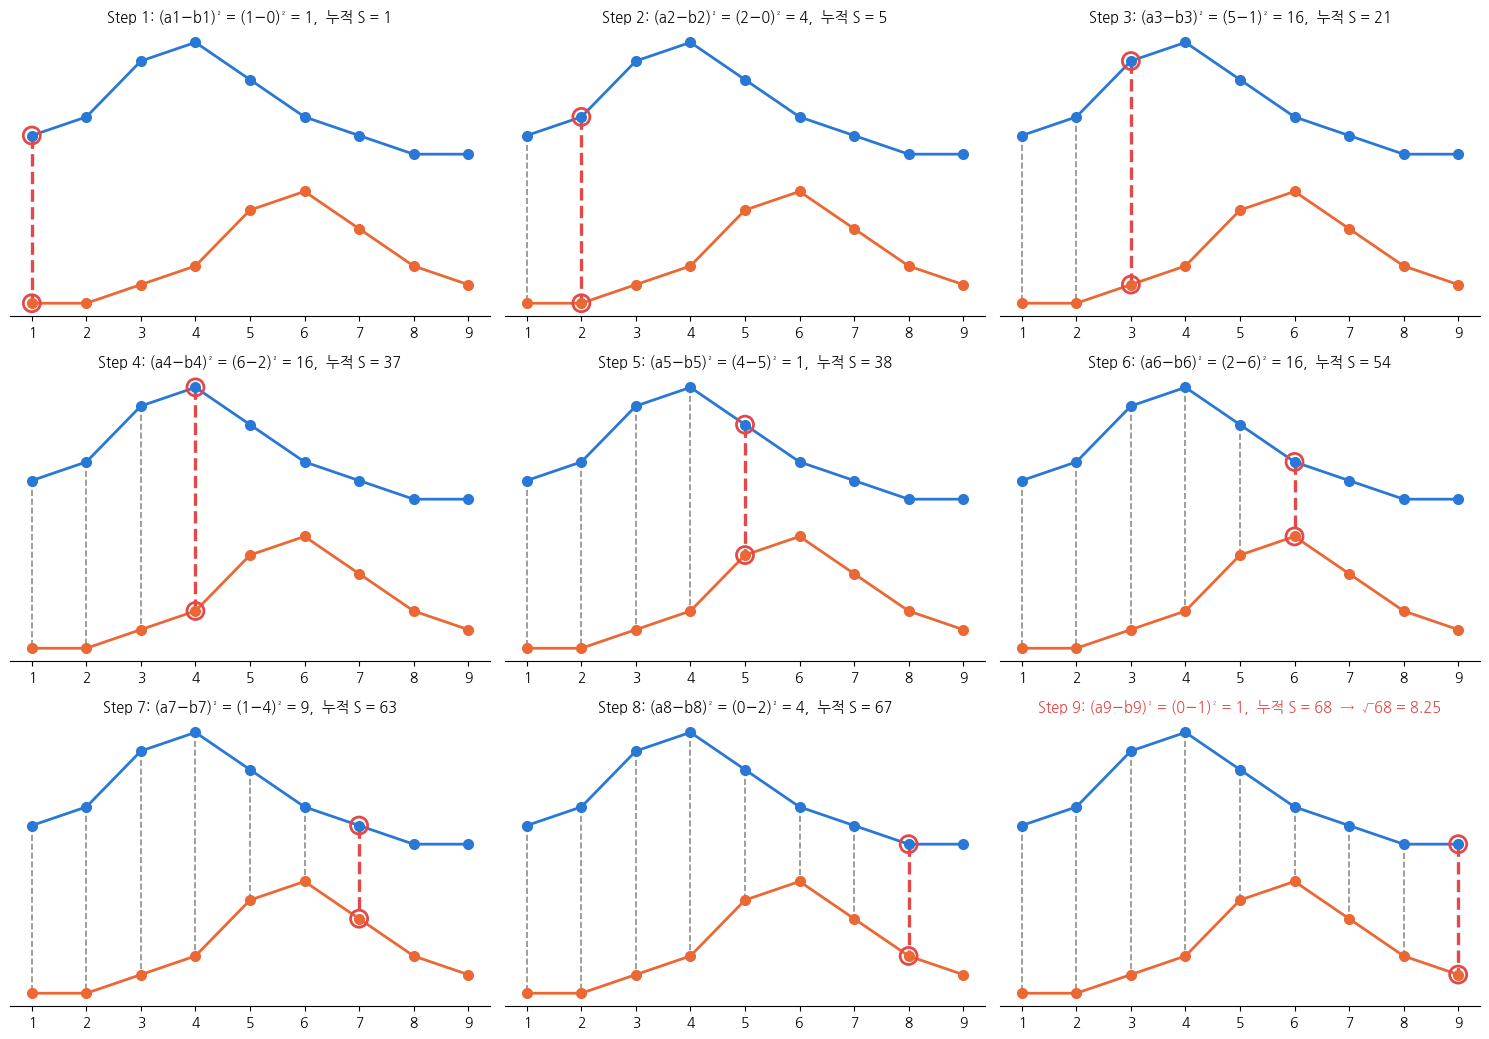

saved: fig01_euclid_steps


In [6]:
fig, axs = plt.subplots(3, 3, figsize=(15, 10.5))
for k, (i, d, s) in enumerate(esteps):
    ax = axs[k // 3, k % 3]
    plot_pair(ax, A, B, [(t, t) for t in range(i + 1)], hl=i)
    ax.scatter([i, i], [A[i], B[i] - 8], s=150, facecolors="none", edgecolors=COL_HL, lw=2, zorder=4)
    tail = f"  →  √{s} = {s**0.5:.2f}" if i == N - 1 else ""
    ax.set_title(f"Step {i+1}: (a{i+1}−b{i+1})² = ({A[i]}−{B[i]})² = {d},  누적 S = {s}{tail}",
                 fontsize=10.5, color=COL_HL if tail else "#0b0b0b")
    ax.set_xlabel("")
fig.tight_layout()
save(fig, "fig01_euclid_steps")

### [5] 그림 2 — DTW DP 테이블 채우기 단계별 캡처

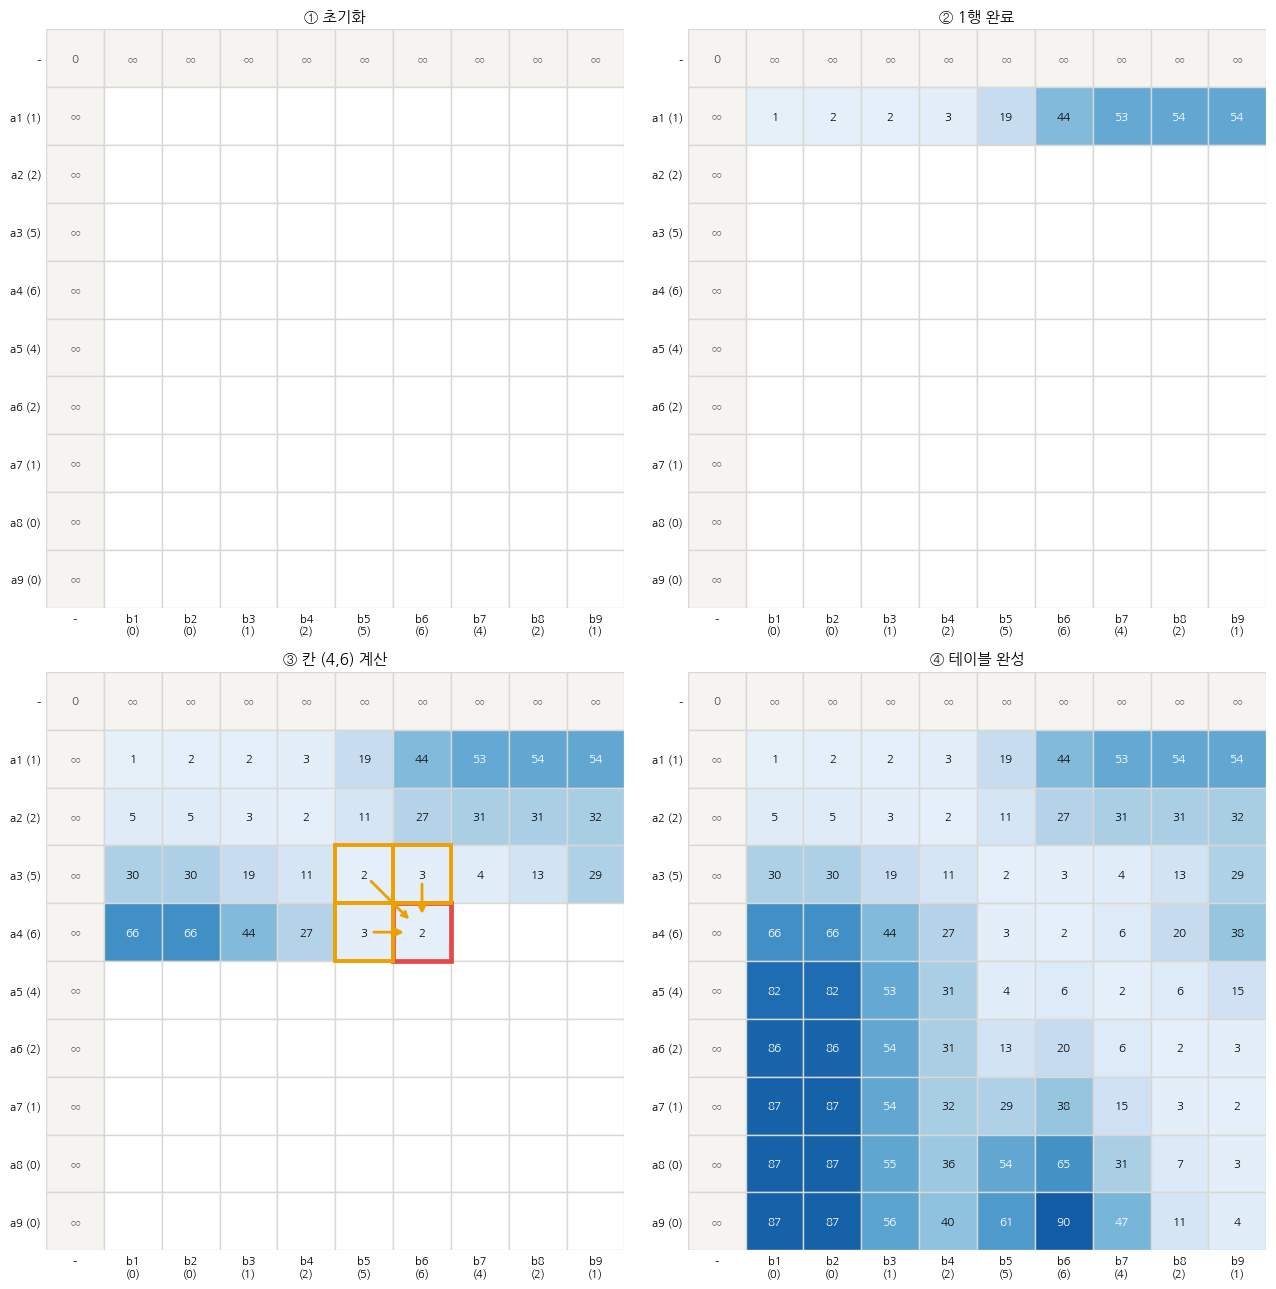

saved: fig02_dtw_steps


In [7]:
CUR = (4, 6)
snap = [0, N, ORDER_AB.index(CUR) + 1, len(ORDER_AB)]
ti = ["① 초기화", "② 1행 완료", f"③ 칸 ({CUR[0]},{CUR[1]}) 계산", "④ 테이블 완성"]
fig, axs = plt.subplots(2, 2, figsize=(13, 13))
for k, ax in enumerate(axs.flat):
    draw_table(ax, A, B, D_AB, set(ORDER_AB[:snap[k]]), cur=CUR if k == 2 else None, title=ti[k], vmax=VMAX)
fig.tight_layout()
save(fig, "fig02_dtw_steps")

### [6] 그림 3 — 역추적(Backtracking)

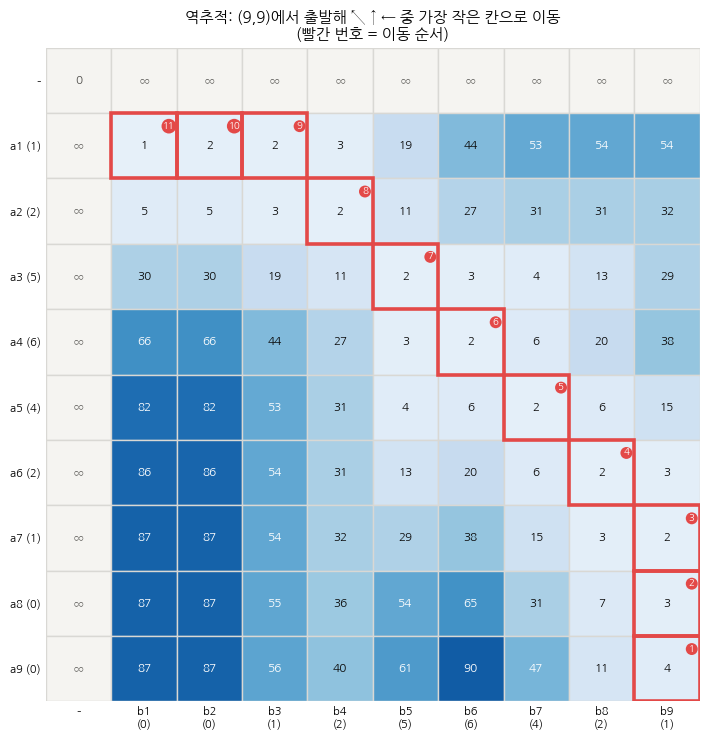

saved: fig03_backtrack
역추적 순서: [(9, 9), (8, 9), (7, 9), (6, 8), (5, 7), (4, 6), (3, 5), (2, 4), (1, 3), (1, 2), (1, 1)]


In [8]:
bt = PATH_AB[::-1]                                  # (9,9)부터 거꾸로
fig, ax = plt.subplots(figsize=(7.5, 7.5))
draw_table(ax, A, B, D_AB, set(ORDER_AB), path=bt, numbers=list(range(1, len(bt) + 1)),
           title="역추적: (9,9)에서 출발해 ↖ ↑ ← 중 가장 작은 칸으로 이동\n(빨간 번호 = 이동 순서)", vmax=VMAX)
fig.tight_layout()
save(fig, "fig03_backtrack")
print("역추적 순서:", bt)

### [7] 그림 4 — 짝짓기 방식 비교 (1:1 vs 1:N)

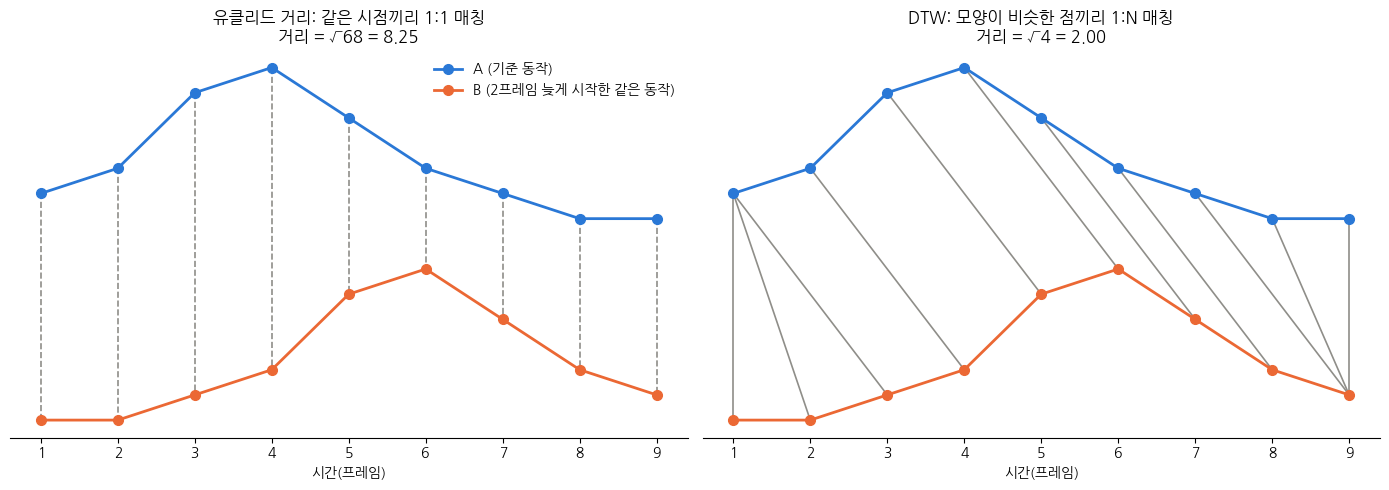

saved: fig04_alignment


In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
plot_pair(ax1, A, B, [(i, i) for i in range(N)],
          f"유클리드 거리: 같은 시점끼리 1:1 매칭\n거리 = √{int(eAB**2)} = {eAB:.2f}")
plot_pair(ax2, A, B, [(i - 1, j - 1) for i, j in PATH_AB],
          f"DTW: 모양이 비슷한 점끼리 1:N 매칭\n거리 = √{int(D_AB[-1,-1])} = {dAB:.2f}", style="-")
ax1.legend(loc="upper right", frameon=False, fontsize=10)
fig.tight_layout()
save(fig, "fig04_alignment")

### [8] 그림 5 — 계산하는 칸 비교 (n칸 vs n²칸)

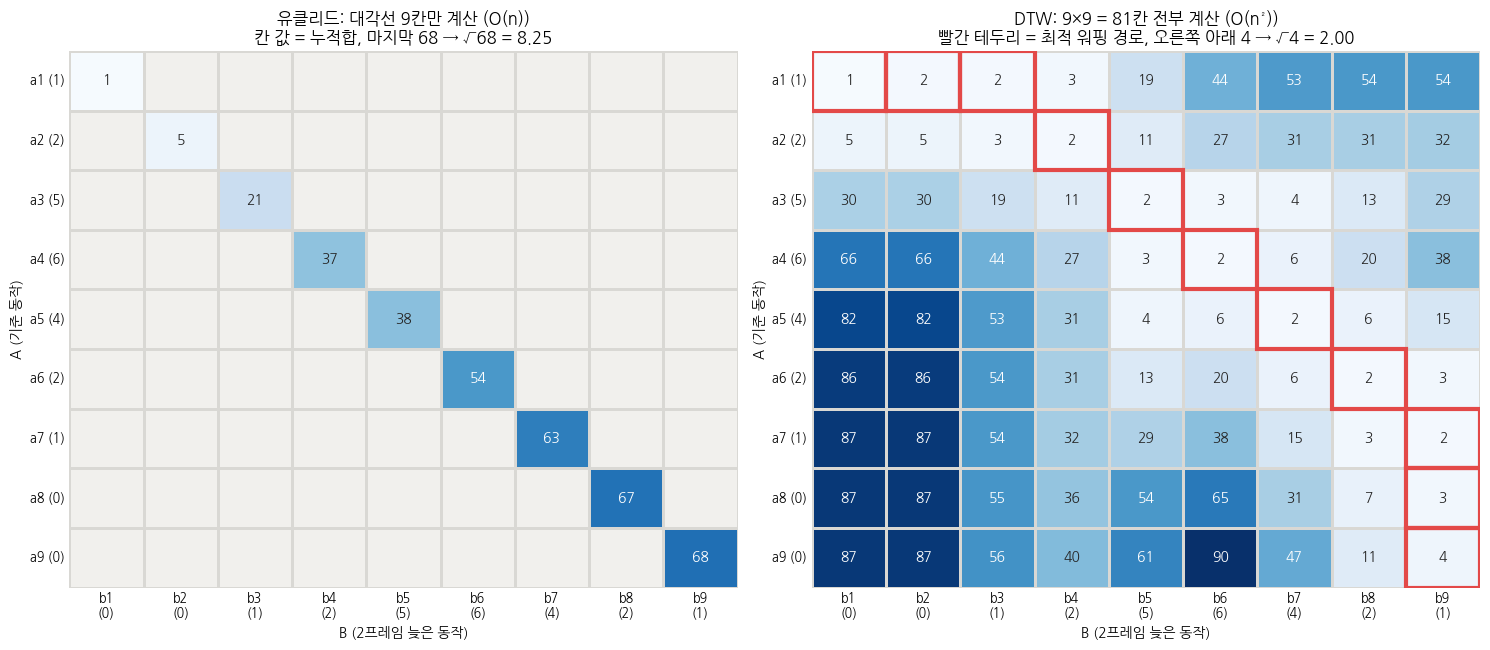

saved: fig05_tables


In [10]:
xt = [f"b{j+1}\n({B[j]})" for j in range(N)]
yt = [f"a{i+1} ({A[i]})" for i in range(N)]
Dm = D_AB[1:, 1:]
vmax = Dm.max()
fig, (ax3, ax4) = plt.subplots(1, 2, figsize=(15, 6.6))
euc_grid = np.full((N, N), np.nan)
for i, d, s in esteps:
    euc_grid[i, i] = s
sns.heatmap(euc_grid, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=vmax, cbar=False, ax=ax3,
            linewidths=1, linecolor=COL_GRID, xticklabels=xt, yticklabels=yt)
ax3.set_facecolor("#f1f0ed")
ax3.set_title(f"유클리드: 대각선 {N}칸만 계산 (O(n))\n칸 값 = 누적합, 마지막 {esteps[-1][2]} → √{esteps[-1][2]} = {eAB:.2f}", fontsize=12)
sns.heatmap(Dm, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=vmax, cbar=False, ax=ax4,
            linewidths=1, linecolor=COL_GRID, xticklabels=xt, yticklabels=yt)
for (i, j) in PATH_AB:
    ax4.add_patch(patches.Rectangle((j - 1, i - 1), 1, 1, fill=False, edgecolor=COL_HL, lw=3))
ax4.set_title(f"DTW: {N}×{N} = {N*N}칸 전부 계산 (O(n²))\n빨간 테두리 = 최적 워핑 경로, 오른쪽 아래 {int(D_AB[-1,-1])} → √{int(D_AB[-1,-1])} = {dAB:.2f}", fontsize=12)
for ax in (ax3, ax4):
    ax.set_xlabel("B (2프레임 늦은 동작)"); ax.set_ylabel("A (기준 동작)")
    ax.tick_params(length=0, labelsize=9)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
save(fig, "fig05_tables")

### [9] 그림 6 — 최종 결과: A와 가장 비슷한 동작은? (A, B, C)

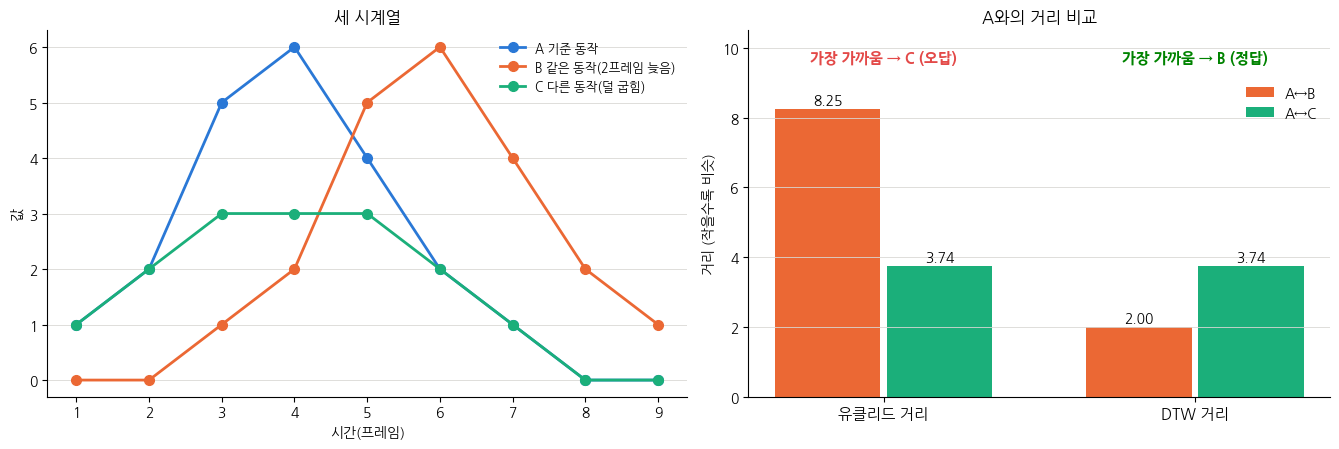

saved: fig06_result


In [11]:
fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
x = np.arange(N)
axs[0].plot(x, A, "-o", color=COL_A, lw=2, ms=7, label="A 기준 동작")
axs[0].plot(x, B, "-o", color=COL_B, lw=2, ms=7, label="B 같은 동작(2프레임 늦음)")
axs[0].plot(x, C, "-o", color=COL_C, lw=2, ms=7, label="C 다른 동작(덜 굽힘)")
axs[0].set_xticks(x); axs[0].set_xticklabels(x + 1)
axs[0].set_xlabel("시간(프레임)"); axs[0].set_ylabel("값")
axs[0].legend(frameon=False, fontsize=9); axs[0].grid(axis="y", color=COL_GRID, lw=0.6)
axs[0].set_title("세 시계열", fontsize=12)
w = 0.34
for k, (vb, vc) in enumerate([(eAB, eAC), (dAB, dAC)]):
    for off, v, col, lab in [(-w / 2 - 0.01, vb, COL_B, "A↔B"), (w / 2 + 0.01, vc, COL_C, "A↔C")]:
        bar = axs[1].bar(k + off, v, w, color=col, label=lab if k == 0 else None)[0]
        axs[1].text(bar.get_x() + w / 2, v + 0.15, f"{v:.2f}", ha="center", fontsize=10)
    pick_c = vc < vb
    axs[1].text(k, 9.6, "가장 가까움 → C (오답)" if pick_c else "가장 가까움 → B (정답)", ha="center",
                fontsize=10.5, fontweight="bold", color=COL_HL if pick_c else "#008300")
axs[1].set_xticks([0, 1]); axs[1].set_xticklabels(["유클리드 거리", "DTW 거리"], fontsize=11)
axs[1].set_ylim(0, 10.5); axs[1].set_ylabel("거리 (작을수록 비슷)")
axs[1].legend(frameon=False, loc="upper right", bbox_to_anchor=(1, 0.88))
axs[1].grid(axis="y", color=COL_GRID, lw=0.6)
axs[1].set_title("A와의 거리 비교", fontsize=12)
fig.tight_layout()
save(fig, "fig06_result")

### [10] 그림 7 — 입력 크기별 실행 시간

n=   50  유클리드    0.018ms  DTW       2.8ms  밴드10%      0.6ms
n=  100  유클리드    0.036ms  DTW      11.8ms  밴드10%      4.6ms
n=  200  유클리드    0.139ms  DTW      51.1ms  밴드10%      9.9ms
n=  400  유클리드    0.145ms  DTW     203.9ms  밴드10%     39.3ms
n=  800  유클리드    0.288ms  DTW     821.0ms  밴드10%    160.6ms
n= 1600  유클리드    1.243ms  DTW    3418.0ms  밴드10%    645.0ms


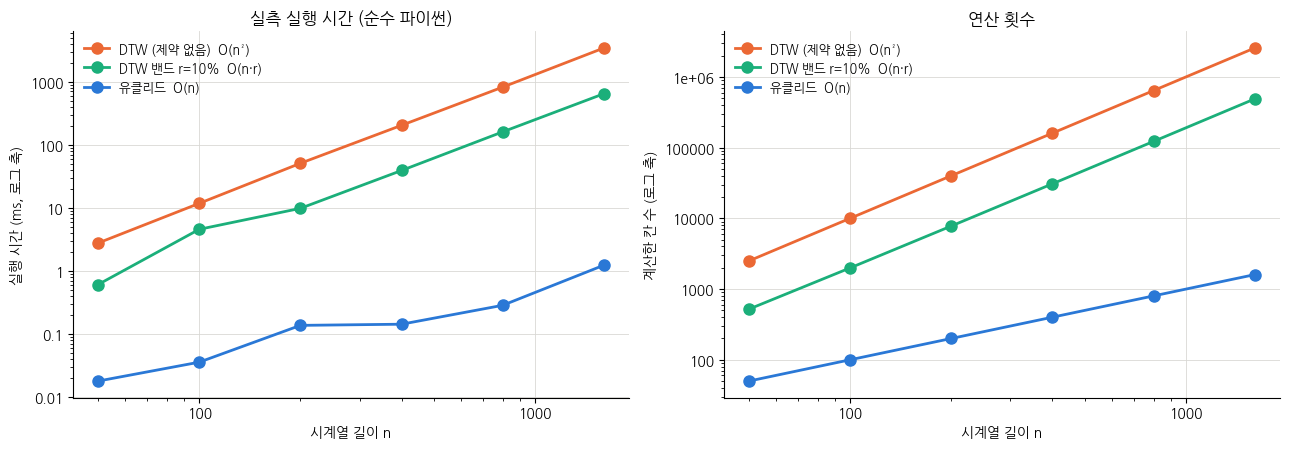

saved: fig07_runtime


In [12]:
def best_time(f, rep=3):
    f()                                   # 워밍업
    ts = []
    for _ in range(rep):
        t0 = time.perf_counter(); f(); ts.append(time.perf_counter() - t0)
    return min(ts)

sizes = [50, 100, 200, 400, 800, 1600]
rng = np.random.default_rng(0)
t_eu, t_full, t_band, c_full, c_band = [], [], [], [], []
for n in sizes:
    a = list(np.cumsum(rng.normal(size=n))); b = list(np.cumsum(rng.normal(size=n)))
    r = max(1, n // 10)
    t_eu.append(best_time(lambda: euclidean(a, b)))
    t_full.append(best_time(lambda: dtw_table(a, b)))
    t_band.append(best_time(lambda: dtw_table(a, b, r)))
    c_full.append(n * n); c_band.append(len(dtw_table(a, b, r)[1]))
    print(f"n={n:5d}  유클리드 {t_eu[-1]*1e3:8.3f}ms  DTW {t_full[-1]*1e3:9.1f}ms  밴드10% {t_band[-1]*1e3:8.1f}ms")
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, ys, yl, tt in [(axs[0], [np.array(t_full) * 1e3, np.array(t_band) * 1e3, np.array(t_eu) * 1e3],
                        "실행 시간 (ms, 로그 축)", "실측 실행 시간 (순수 파이썬)"),
                       (axs[1], [c_full, c_band, sizes], "계산한 칸 수 (로그 축)", "연산 횟수")]:
    ax.loglog(sizes, ys[0], "-o", color=COL_B, lw=2, ms=8, label="DTW (제약 없음)  O(n²)")
    ax.loglog(sizes, ys[1], "-o", color=COL_C, lw=2, ms=8, label="DTW 밴드 r=10%  O(n·r)")
    ax.loglog(sizes, ys[2], "-o", color=COL_A, lw=2, ms=8, label="유클리드  O(n)")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:g}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:g}"))
    ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, p: ""))
    ax.set_xlabel("시계열 길이 n"); ax.set_ylabel(yl); ax.set_title(tt, fontsize=12)
    ax.legend(frameon=False, fontsize=9); ax.grid(color=COL_GRID, lw=0.6)
fig.tight_layout()
save(fig, "fig07_runtime")

### [11] 그림 8 — 사코-치바 밴드 (r = 0, 1, 2, 제약 없음)

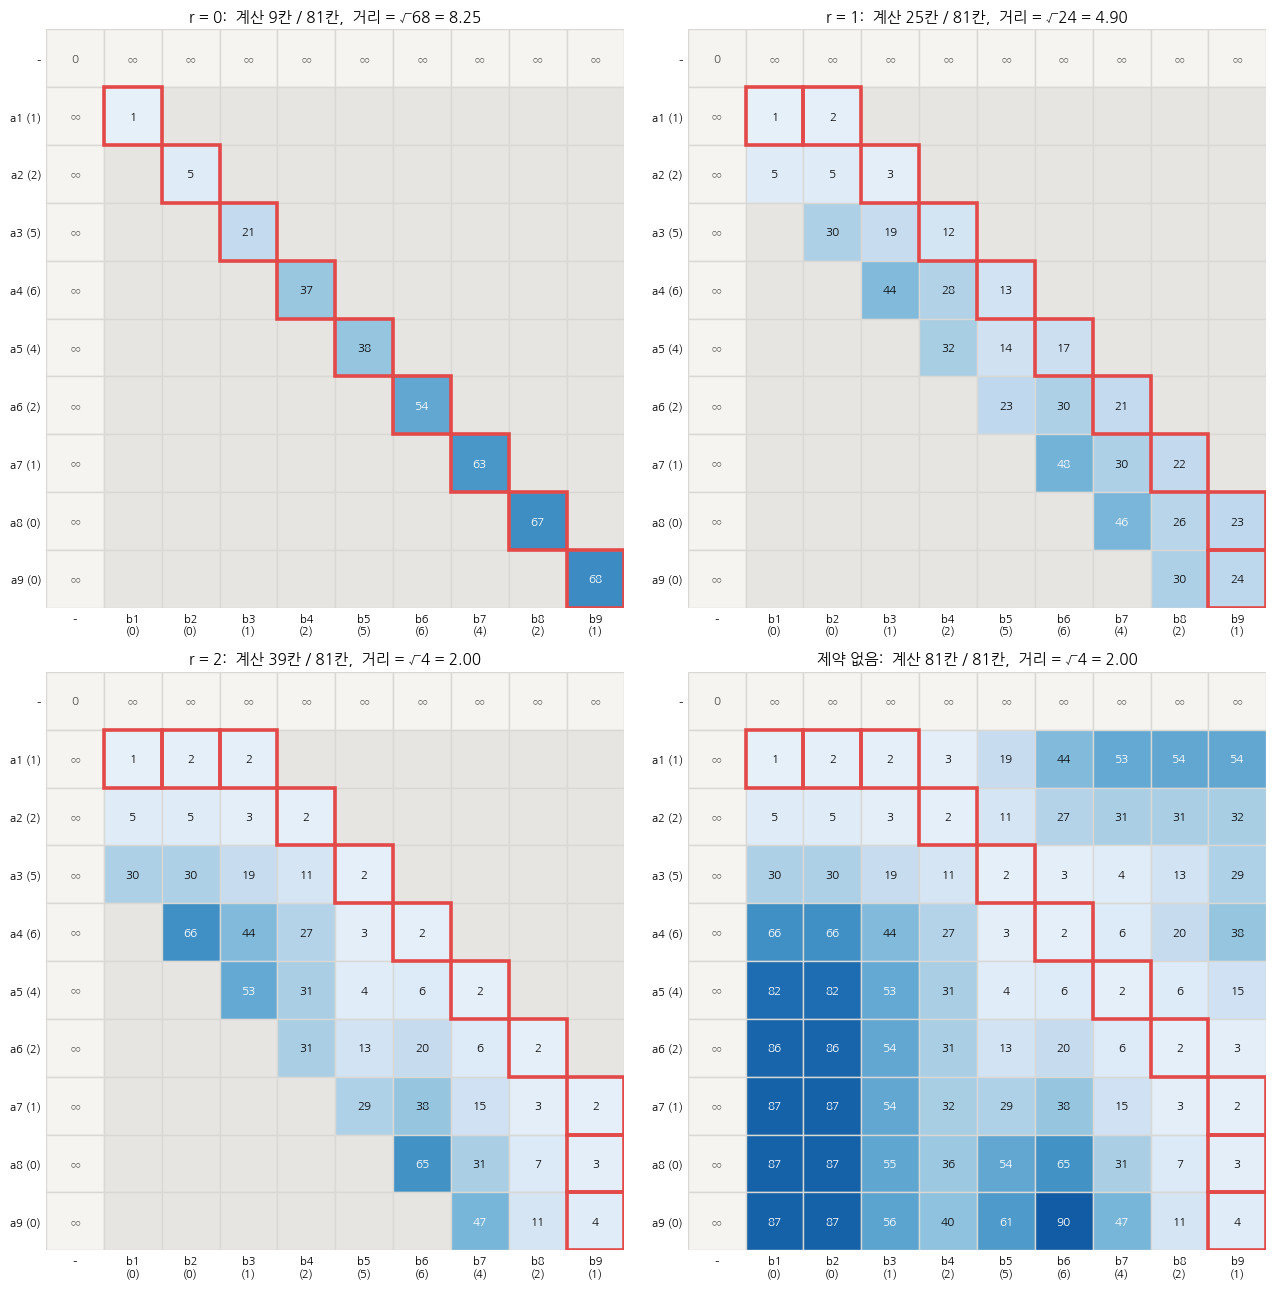

saved: fig08_band
밴드: [(0, 9, 68, np.float64(8.246211251235321)), (1, 25, 24, np.float64(4.898979485566356)), (2, 39, 4, np.float64(2.0)), (None, 81, 4, np.float64(2.0))]


In [13]:
fig, axs = plt.subplots(2, 2, figsize=(13, 13))
BAND = []
for ax, r in zip(axs.flat, [0, 1, 2, None]):
    Dr, ordr = dtw_table(A, B, r)
    pth = backtrack(Dr)
    dist = Dr[-1, -1] ** 0.5
    BAND.append((r, len(ordr), int(Dr[-1, -1]), dist))
    nm = "제약 없음" if r is None else f"r = {r}"
    draw_table(ax, A, B, Dr, set(ordr), path=pth, band=r, vmax=VMAX,
               title=f"{nm}:  계산 {len(ordr)}칸 / {N*N}칸,  거리 = √{int(Dr[-1,-1])} = {dist:.2f}")
fig.tight_layout()
save(fig, "fig08_band")
print("밴드:", BAND)

### [12] 그림 9 — 새 프레임이 들어올 때 계산하는 칸

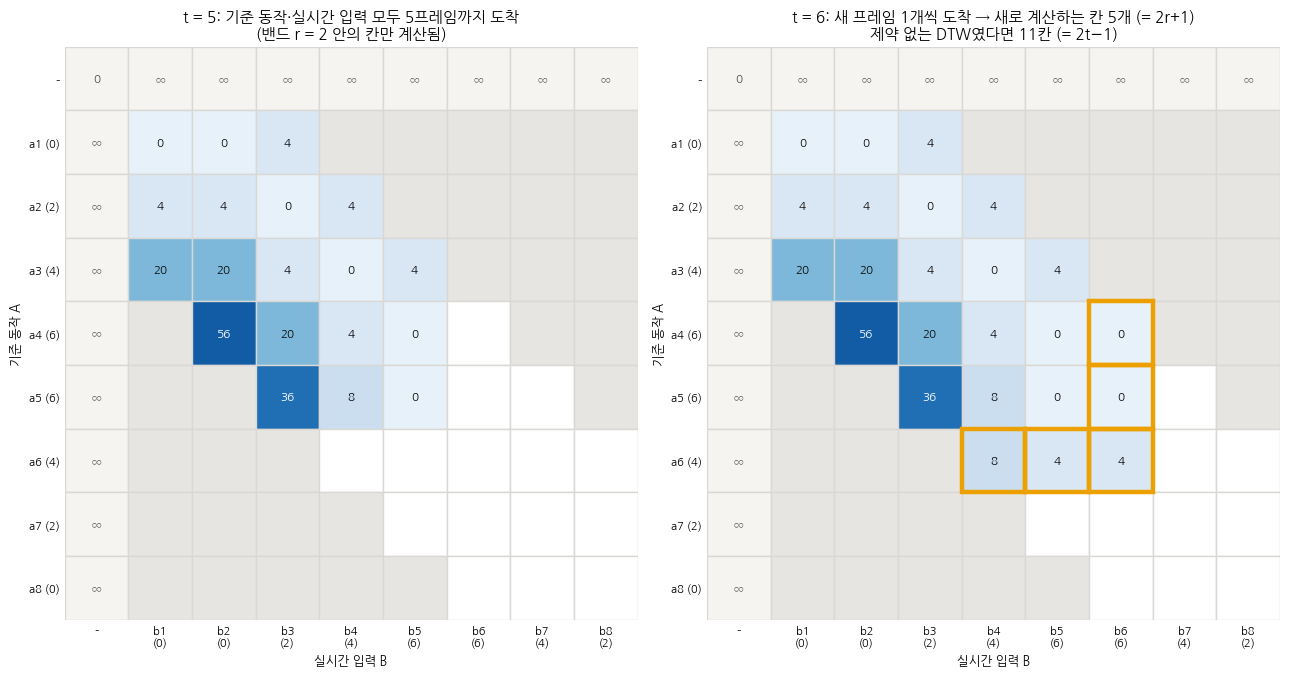

saved: fig09_stream_step
새로 계산한 칸: [(4, 6), (5, 6), (6, 4), (6, 5), (6, 6)] D 값: [0, 0, 8, 4, 4]


In [14]:
# 작은 예제 (원소 8개): 실시간 입력 B는 기준 동작 A를 1프레임 늦게 따라 함.
REF_S = [0, 2, 4, 6, 6, 4, 2, 0]      # 기준 동작
USR_S = [0, 0, 2, 4, 6, 6, 4, 2]      # 실시간 입력: 같은 동작을 1프레임 늦게
R_S = 2
D_S, ORD_S = dtw_table(REF_S, USR_S, R_S)

def cells_upto(t, r=None):
    """두 시계열이 t프레임까지 들어왔을 때 계산된 칸들"""
    return {(i, j) for (i, j) in ORD_S if i <= t and j <= t} if r is not None else \
           {(i, j) for i in range(1, t + 1) for j in range(1, t + 1)}

T0 = 5
old = cells_upto(T0, R_S); new = cells_upto(T0 + 1, R_S) - old
full_new = 2 * (T0 + 1) - 1
fig, axs = plt.subplots(1, 2, figsize=(13, 6.6))
draw_table(axs[0], REF_S, USR_S, D_S, old, band=R_S, vmax=40,
           title=f"t = {T0}: 기준 동작·실시간 입력 모두 {T0}프레임까지 도착\n(밴드 r = {R_S} 안의 칸만 계산됨)")
draw_table(axs[1], REF_S, USR_S, D_S, old | new, band=R_S, vmax=40,
           title=f"t = {T0+1}: 새 프레임 1개씩 도착 → 새로 계산하는 칸 {len(new)}개 (= 2r+1)\n"
                 f"제약 없는 DTW였다면 {full_new}칸 (= 2t−1)")
for (i, j) in new:
    axs[1].add_patch(patches.Rectangle((j, i), 1, 1, fill=False, edgecolor=COL_NB, lw=3.2))
for ax in axs:
    ax.set_xlabel("실시간 입력 B", fontsize=9)
    ax.set_ylabel("기준 동작 A", fontsize=9)
fig.tight_layout()
save(fig, "fig09_stream_step")
print("새로 계산한 칸:", sorted(new), "D 값:", [int(D_S[i, j]) for i, j in sorted(new)])

### [13] 그림 10 — 실시간 처리에서 프레임당 계산량

칸당 1.335μs, 예산 33.3ms, 제약 없는 DTW가 예산을 넘는 시점 6.9분, 밴드 프레임당 0.108ms


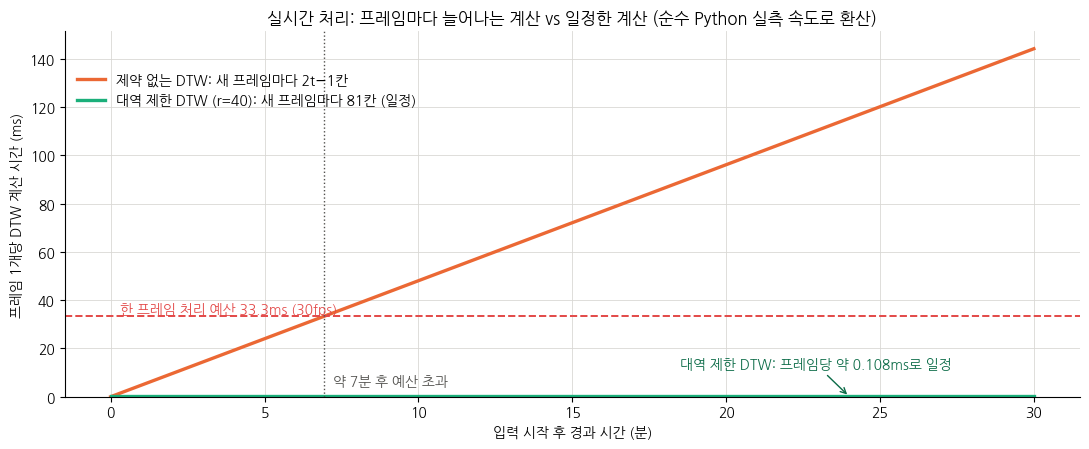

saved: fig10_realtime_cost


In [15]:
FPS = 30                                                  # 카메라 프레임 속도
US_PER_CELL = t_full[-1] / (sizes[-1] ** 2) * 1e6         # [10]에서 잰 칸 1개당 시간(μs)
BUDGET_MS = 1000 / FPS                                    # 한 프레임 처리 예산 33.3ms
R_RT = 40
minutes = np.linspace(0, 30, 301)
tf = minutes * 60 * FPS                                   # 경과 프레임 수
full_ms = (2 * tf - 1).clip(min=1) * US_PER_CELL / 1000   # 새 프레임마다 2t−1칸
band_ms = np.full_like(minutes, (2 * R_RT + 1) * US_PER_CELL / 1000)
cross_min = (BUDGET_MS * 1000 / US_PER_CELL + 1) / 2 / FPS / 60
print(f"칸당 {US_PER_CELL:.3f}μs, 예산 {BUDGET_MS:.1f}ms, 제약 없는 DTW가 예산을 넘는 시점 {cross_min:.1f}분, "
      f"밴드 프레임당 {band_ms[0]:.3f}ms")
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(minutes, full_ms, color=COL_B, lw=2.4, label="제약 없는 DTW: 새 프레임마다 2t−1칸")
ax.plot(minutes, band_ms, color=COL_C, lw=2.4, label=f"대역 제한 DTW (r={R_RT}): 새 프레임마다 {2*R_RT+1}칸 (일정)")
ax.axhline(BUDGET_MS, color=COL_HL, ls="--", lw=1.4)
ax.text(0.3, BUDGET_MS + 1.2, f"한 프레임 처리 예산 {BUDGET_MS:.1f}ms (30fps)", color=COL_HL, fontsize=10)
ax.axvline(cross_min, color=COL_TXT2, ls=":", lw=1)
ax.text(cross_min + 0.3, 5, f"약 {cross_min:.0f}분 후 예산 초과", fontsize=10, color=COL_TXT2)
ax.annotate(f"대역 제한 DTW: 프레임당 약 {band_ms[0]:.3f}ms로 일정", (24, band_ms[0]), xytext=(18.5, 12),
            fontsize=10, color="#0b6b47", arrowprops=dict(arrowstyle="->", color="#0b6b47"))
ax.set_xlabel("입력 시작 후 경과 시간 (분)"); ax.set_ylabel("프레임 1개당 DTW 계산 시간 (ms)")
ax.set_title("실시간 처리: 프레임마다 늘어나는 계산 vs 일정한 계산 (순수 Python 실측 속도로 환산)", fontsize=12)
ax.legend(frameon=False, fontsize=10, loc="upper left", bbox_to_anchor=(0, 0.92)); ax.grid(color=COL_GRID, lw=0.6)
ax.set_ylim(0, max(full_ms) * 1.05)
fig.tight_layout()
save(fig, "fig10_realtime_cost")

### [14] 그림 11 — 자세 교정 적용: 현실을 단순화한 가정 그림

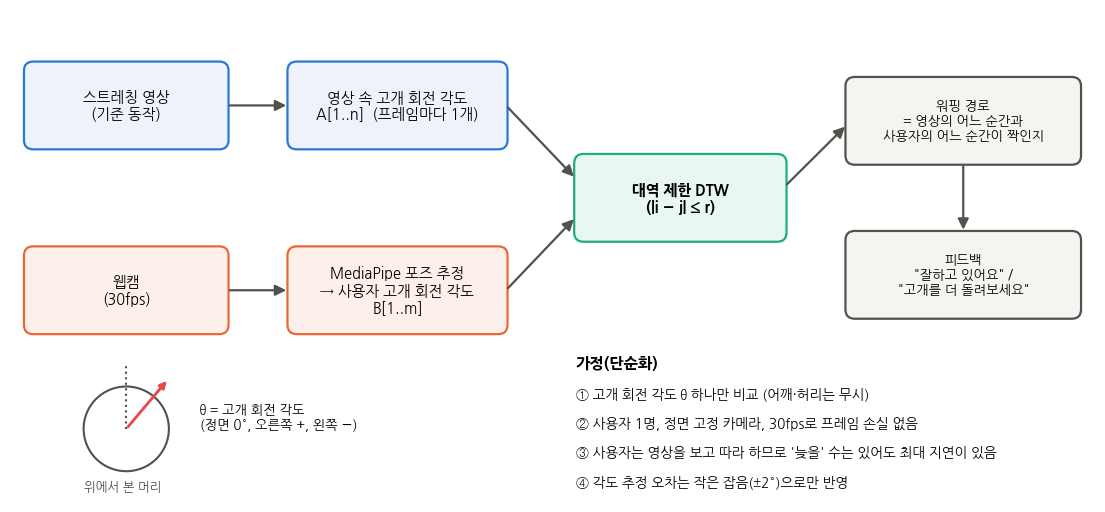

saved: fig11_assumption


In [16]:
from matplotlib.patches import FancyBboxPatch, Circle, FancyArrowPatch

def box(ax, x, y, w, h, text, fc="#eef3fb", ec=COL_A, fs=10.5, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc=fc, ec=ec, lw=1.6))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs,
            fontweight="bold" if bold else "normal")

def arrow(ax, x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=16, color=COL_TXT2, lw=1.6))

fig, ax = plt.subplots(figsize=(14, 6.4))
ax.set_xlim(0, 14); ax.set_ylim(0, 6.4); ax.axis("off")
# 위쪽 줄: 기준 영상
box(ax, 0.2, 4.6, 2.6, 1.1, "스트레칭 영상\n(기준 동작)", fc="#eef3fb")
box(ax, 3.6, 4.6, 2.8, 1.1, "영상 속 고개 회전 각도\nA[1..n]  (프레임마다 1개)", fc="#eef3fb")
arrow(ax, 2.8, 5.15, 3.6, 5.15)
# 아래 줄: 사용자
box(ax, 0.2, 2.2, 2.6, 1.1, "웹캠\n(30fps)", fc="#fdf0ea", ec=COL_B)
box(ax, 3.6, 2.2, 2.8, 1.1, "MediaPipe 포즈 추정\n→ 사용자 고개 회전 각도\nB[1..m]", fc="#fdf0ea", ec=COL_B)
arrow(ax, 2.8, 2.75, 3.6, 2.75)
# 비교
box(ax, 7.3, 3.4, 2.7, 1.1, "대역 제한 DTW\n(|i − j| ≤ r)", fc="#e9f7f1", ec=COL_C, bold=True)
arrow(ax, 6.4, 5.15, 7.3, 4.2); arrow(ax, 6.4, 2.75, 7.3, 3.7)
box(ax, 10.8, 4.4, 3.0, 1.1, "워핑 경로\n= 영상의 어느 순간과\n사용자의 어느 순간이 짝인지", fc="#f5f4f1", ec=COL_TXT2, fs=9.5)
box(ax, 10.8, 2.4, 3.0, 1.1, "피드백\n\"잘하고 있어요\" /\n\"고개를 더 돌려보세요\"", fc="#f5f4f1", ec=COL_TXT2, fs=9.5)
arrow(ax, 10.0, 4.1, 10.8, 4.9); arrow(ax, 12.3, 4.4, 12.3, 3.5)
# 위에서 본 머리 그림 (고개 회전 각도 정의)
cx, cy = 1.5, 0.95
ax.add_patch(Circle((cx, cy), 0.55, fc="white", ec=COL_TXT2, lw=1.5))
ax.plot([cx, cx], [cy, cy + 0.85], ":", color=COL_TXT2)
ang = np.deg2rad(40)
ax.annotate("", xy=(cx + 0.85 * np.sin(ang), cy + 0.85 * np.cos(ang)), xytext=(cx, cy),
            arrowprops=dict(arrowstyle="-|>", color=COL_HL, lw=2))
ax.text(cx + 0.95, cy + 0.15, "θ = 고개 회전 각도\n(정면 0°, 오른쪽 +, 왼쪽 −)", fontsize=9.5, va="center")
ax.text(cx - 0.55, cy - 0.8, "위에서 본 머리", fontsize=9, color=COL_TXT2)
# 가정
ax.text(7.3, 1.75, "가정(단순화)", fontsize=11, fontweight="bold")
for k, t_ in enumerate(["① 고개 회전 각도 θ 하나만 비교 (어깨·허리는 무시)",
                        "② 사용자 1명, 정면 고정 카메라, 30fps로 프레임 손실 없음",
                        "③ 사용자는 영상을 보고 따라 하므로 '늦을' 수는 있어도 최대 지연이 있음",
                        "④ 각도 추정 오차는 작은 잡음(±2°)으로만 반영"]):
    ax.text(7.3, 1.35 - k * 0.38, t_, fontsize=9.8)
save(fig, "fig11_assumption")

### [15] 가상 스트레칭 데이터 설정값

In [17]:
# ※ 아래 각도 데이터는 실측이 아닌 '가상 데이터'다.
FPS = 30                        # 카메라 프레임 속도
TARGET = 60                     # 목표 회전 각도(°)
TURN_SEC, HOLD_SEC, REST_SEC = 1.5, 2.0, 1.0   # 돌리기·유지·휴식 시간(초)
NUM_USERS = 200                 # 가상 사용자 수
LAG_RANGE = (0.2, 1.2)          # 반응 지연 범위(초): 영상보다 이만큼 늦게 시작
SPEED_RANGE = (0.85, 1.15)      # 동작 속도 배율 범위
WEAK_ANGLE = 40                 # '덜 돌리는' 사용자가 도달하는 각도(°)
NOISE_DEG = 2.0                 # 각도 측정 잡음 크기(°)
SEED = 3                        # 난수 시드 (같은 값이면 매번 같은 결과)
FEEDBACK_RATIO = 0.85           # 목표의 이 비율보다 덜 돌리면 "더 돌려보세요"

### [16] 가상 스트레칭 데이터를 만드는 함수

In [18]:
def smooth_step(t):
    t = np.clip(t, 0, 1)
    return t * t * (3 - 2 * t)

def neck_rotation(amp_r=TARGET, amp_l=TARGET, speed=1.0, lag=0.0, up_r=TURN_SEC, total=13.0, noise=0.0, rng=None):
    """목 돌리기 1세트(각도, 도): 준비 0.5초 → 오른쪽으로 돌림(1.5초) → 유지(2초) → 복귀(1.5초)
       → 휴식(1초) → 왼쪽으로 돌림 → 유지 → 복귀.  lag = 영상보다 늦게 시작한 시간(초)"""
    t = np.arange(int(total * FPS)) / FPS
    s = (t - 0.5 - lag) / speed
    up, hold, rest = TURN_SEC, HOLD_SEC, REST_SEC
    def bump(s0, amp, u=up):
        x = s - s0
        return amp * (smooth_step(x / u) - smooth_step((x - u - hold) / up))
    y = bump(0, amp_r, up_r) - bump(up * 2 + hold + rest, amp_l)
    if rng is not None:
        y = y + rng.normal(0, noise, len(t))
    return y

REF = neck_rotation()                                # 기준 영상
NREF = len(REF)
HOLD = {"오른쪽": np.where(REF >= 0.95 * TARGET)[0], "왼쪽": np.where(REF <= -0.95 * TARGET)[0]}   # 영상의 '유지' 구간

def pairs_euclid(usr):
    return [(i, i) for i in range(len(REF))]

def pairs_dtw(usr, r=None):
    D, _ = dtw_table(list(REF), list(usr), r)
    return [(i - 1, j - 1) for i, j in backtrack(D)]

def feedback(pairs, usr, thr=FEEDBACK_RATIO):
    """영상의 '유지' 구간과 짝지어진 사용자 프레임의 평균 각도로 피드백을 만든다"""
    out = {}
    for side, idx in HOLD.items():
        s = set(idx)
        m = float(np.mean([abs(usr[j]) for i, j in pairs if i in s]))
        out[side] = (m, m < thr * TARGET)      # True = "더 돌려보세요"
    return out

### [17] 그림 12 — 같은 시점 비교 vs 대역 제한 DTW 피드백

1:1 비교 (같은 시점끼리 비교) {'오른쪽': (48.503690894811655, True), '왼쪽': (23.317098286917282, True)}
대역 제한 DTW (r = 40프레임 = 1.3초) {'오른쪽': (59.71649970191727, False), '왼쪽': (41.45471496268115, True)}


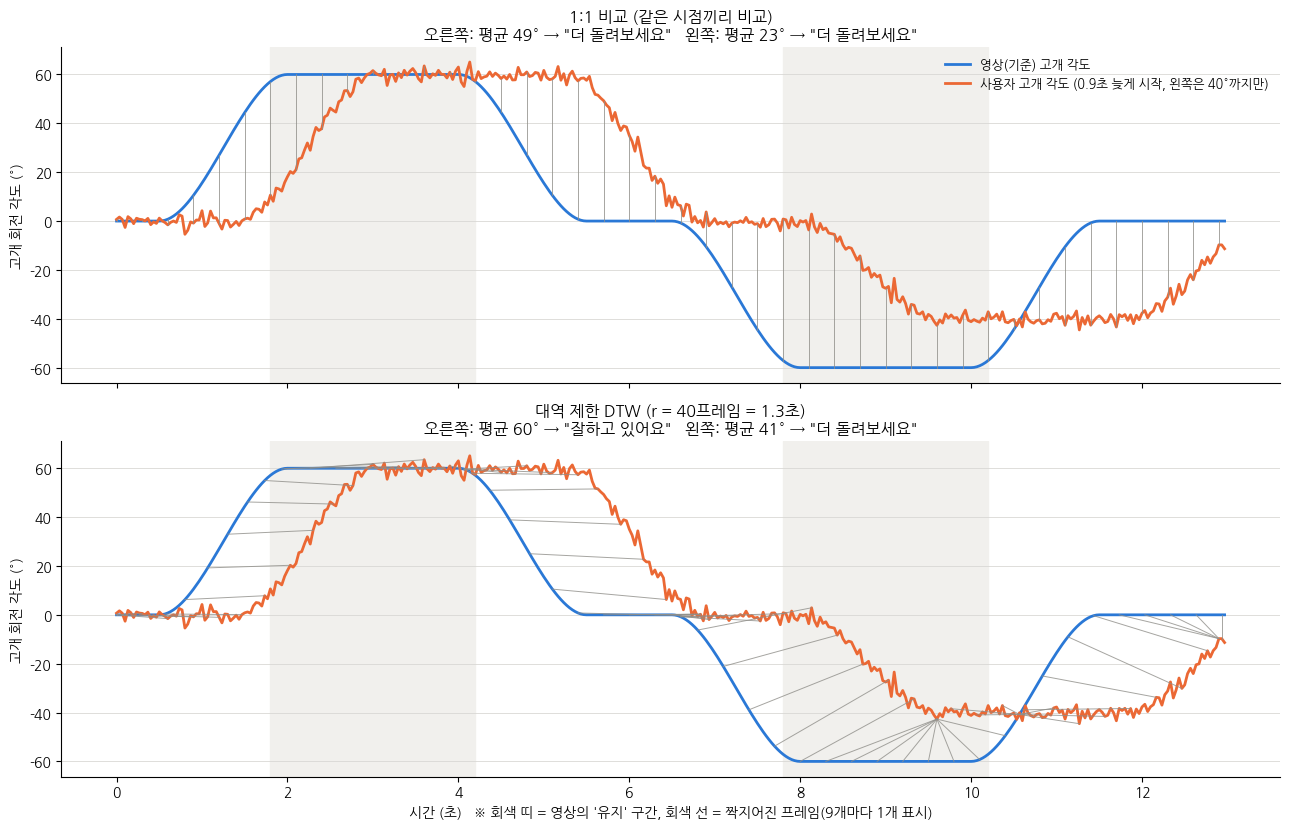

saved: fig12_feedback


In [19]:
rng = np.random.default_rng(1)
USR = neck_rotation(amp_r=TARGET, amp_l=WEAK_ANGLE, lag=0.9, speed=1.1, noise=NOISE_DEG, rng=rng)  # 늦게 + 왼쪽은 덜 돌림
t = np.arange(NREF) / FPS
R_GOOD = 40
fig, axs = plt.subplots(2, 1, figsize=(13, 8.4), sharex=True)
for ax, (name, pairs) in zip(axs, [("1:1 비교 (같은 시점끼리 비교)", pairs_euclid(USR)),
                                    (f"대역 제한 DTW (r = {R_GOOD}프레임 = {R_GOOD/FPS:.1f}초)", pairs_dtw(USR, R_GOOD))]):
    ax.plot(t, REF, color=COL_A, lw=2, label="영상(기준) 고개 각도")
    ax.plot(t, USR, color=COL_B, lw=2, label=f"사용자 고개 각도 (0.9초 늦게 시작, 왼쪽은 {WEAK_ANGLE}°까지만)")
    for k, (i, j) in enumerate(pairs):
        if k % 9 == 0:
            ax.plot([i / FPS, j / FPS], [REF[i], USR[j]], color="#8f8e89", lw=0.7, alpha=0.8)
    for side, idx in HOLD.items():
        ax.axvspan(idx[0] / FPS, idx[-1] / FPS, color="#f1f0ed", zorder=0)
    fb = feedback(pairs, USR)
    msg = "   ".join(f"{s}: 평균 {m:.0f}° → " + ("\"더 돌려보세요\"" if bad else "\"잘하고 있어요\"")
                     for s, (m, bad) in fb.items())
    ax.set_title(f"{name}\n{msg}", fontsize=11.5)
    ax.set_ylabel("고개 회전 각도 (°)"); ax.grid(axis="y", color=COL_GRID, lw=0.6)
    print(name, fb)
axs[0].legend(frameon=False, fontsize=9, loc="upper right")
axs[1].set_xlabel("시간 (초)   ※ 회색 띠 = 영상의 '유지' 구간, 회색 선 = 짝지어진 프레임(9개마다 1개 표시)")
fig.tight_layout()
save(fig, "fig12_feedback")

### [18] 그림 13 — 밴드 폭 r에 따른 피드백 정확도와 계산량

   1:1  정확도  56.5%  칸     390 (  0.3%)
   r=5  정확도  75.0%  칸    4260 (  2.8%)
  r=10  정확도  86.5%  칸    8080 (  5.3%)
  r=15  정확도  94.0%  칸   11850 (  7.8%)
  r=20  정확도  94.5%  칸   15570 ( 10.2%)
  r=30  정확도  99.0%  칸   22860 ( 15.0%)
  r=40  정확도 100.0%  칸   29950 ( 19.7%)
  r=50  정확도 100.0%  칸   36840 ( 24.2%)
  r=80  정확도 100.0%  칸   56310 ( 37.0%)
 제약 없음  정확도 100.0%  칸  152100 (100.0%)


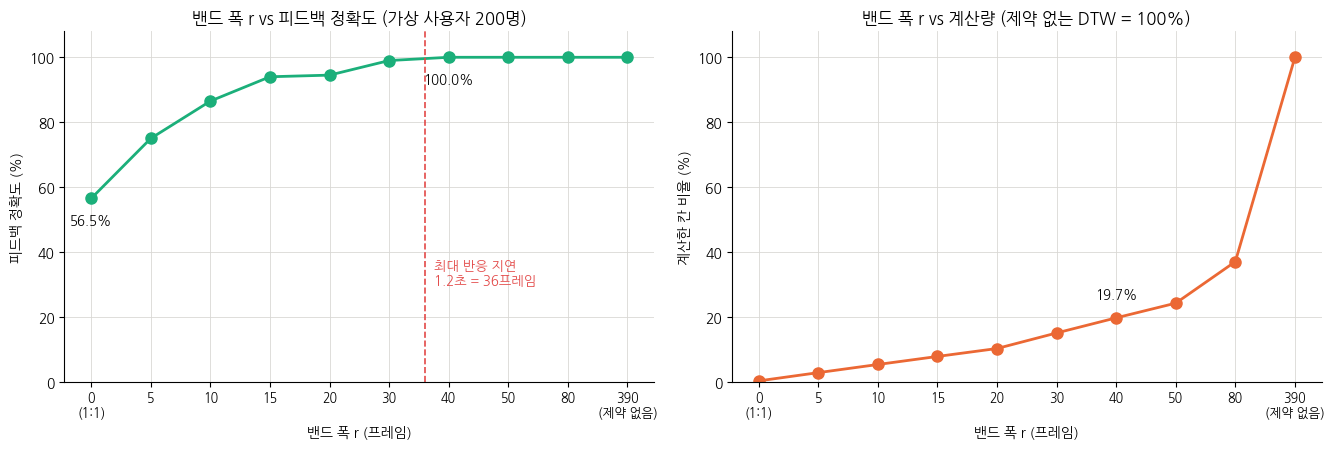

saved: fig13_band_sweep


In [20]:
prng = random.Random(SEED); nrng = np.random.default_rng(SEED)
CASES = []
for _ in range(NUM_USERS):                   # 가상 사용자
    lag = prng.uniform(*LAG_RANGE)           # 반응 지연
    speed = prng.uniform(*SPEED_RANGE)       # 동작 속도
    weak = prng.choice(["없음", "오른쪽", "왼쪽"])
    usr = neck_rotation(WEAK_ANGLE if weak == "오른쪽" else TARGET, WEAK_ANGLE if weak == "왼쪽" else TARGET,
                        speed, lag, noise=NOISE_DEG, rng=nrng)
    CASES.append((usr, weak, lag))

def accuracy(method):
    ok = 0
    for usr, weak, _ in CASES:
        fb = feedback(method(usr), usr)
        ok += all(fb[s][1] == (weak == s) for s in HOLD)
    return ok / len(CASES)

SWEEP_B = [("1:1", 0, accuracy(pairs_euclid), NREF)]
for r in [5, 10, 15, 20, 30, 40, 50, 80]:
    SWEEP_B.append((f"r={r}", r, accuracy(lambda u, r=r: pairs_dtw(u, r)), len(dtw_table([0] * NREF, [0] * NREF, r)[1])))
SWEEP_B.append(("제약 없음", NREF, accuracy(pairs_dtw), NREF * NREF))
for row in SWEEP_B:
    print(f"{row[0]:>6s}  정확도 {row[2]*100:5.1f}%  칸 {row[3]:7d} ({row[3]/NREF**2*100:5.1f}%)")

fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.6))
xs = list(range(len(SWEEP_B)))                      # 눈금을 같은 간격으로 배치
labels = ["0\n(1:1)"] + [str(row[1]) for row in SWEEP_B[1:-1]] + [f"{NREF}\n(제약 없음)"]
axs[0].plot(xs, [row[2] * 100 for row in SWEEP_B], "-o", color=COL_C, lw=2, ms=8)
MAX_LAG_F = LAG_RANGE[1] * FPS                      # 최대 반응 지연(프레임)
pos36 = float(np.interp(MAX_LAG_F, [row[1] for row in SWEEP_B], xs))
axs[0].axvline(pos36, color=COL_HL, ls="--", lw=1.2)
axs[0].text(pos36 + 0.15, 30, f"최대 반응 지연\n{LAG_RANGE[1]}초 = {MAX_LAG_F:.0f}프레임", color=COL_HL, fontsize=9.5)
for k in [0, 6]:
    axs[0].text(xs[k], SWEEP_B[k][2] * 100 - 8, f"{SWEEP_B[k][2]*100:.1f}%", ha="center", fontsize=9.5)
axs[0].set_ylim(0, 108); axs[0].set_ylabel("피드백 정확도 (%)")
axs[0].set_title("밴드 폭 r vs 피드백 정확도 (가상 사용자 200명)", fontsize=12)
axs[1].plot(xs, [row[3] / NREF ** 2 * 100 for row in SWEEP_B], "-o", color=COL_B, lw=2, ms=8)
axs[1].text(xs[6], SWEEP_B[6][3] / NREF ** 2 * 100 + 6, f"{SWEEP_B[6][3]/NREF**2*100:.1f}%", ha="center", fontsize=9.5)
axs[1].set_ylim(0, 108); axs[1].set_ylabel("계산한 칸 비율 (%)")
axs[1].set_title("밴드 폭 r vs 계산량 (제약 없는 DTW = 100%)", fontsize=12)
for ax in axs:
    ax.set_xticks(xs); ax.set_xticklabels(labels, fontsize=9)
    ax.set_xlabel("밴드 폭 r (프레임)"); ax.grid(color=COL_GRID, lw=0.6)
fig.tight_layout()
save(fig, "fig13_band_sweep")

### [19] 그림 14 — 밴드가 반응 지연보다 좁을 때 생기는 잘못된 피드백

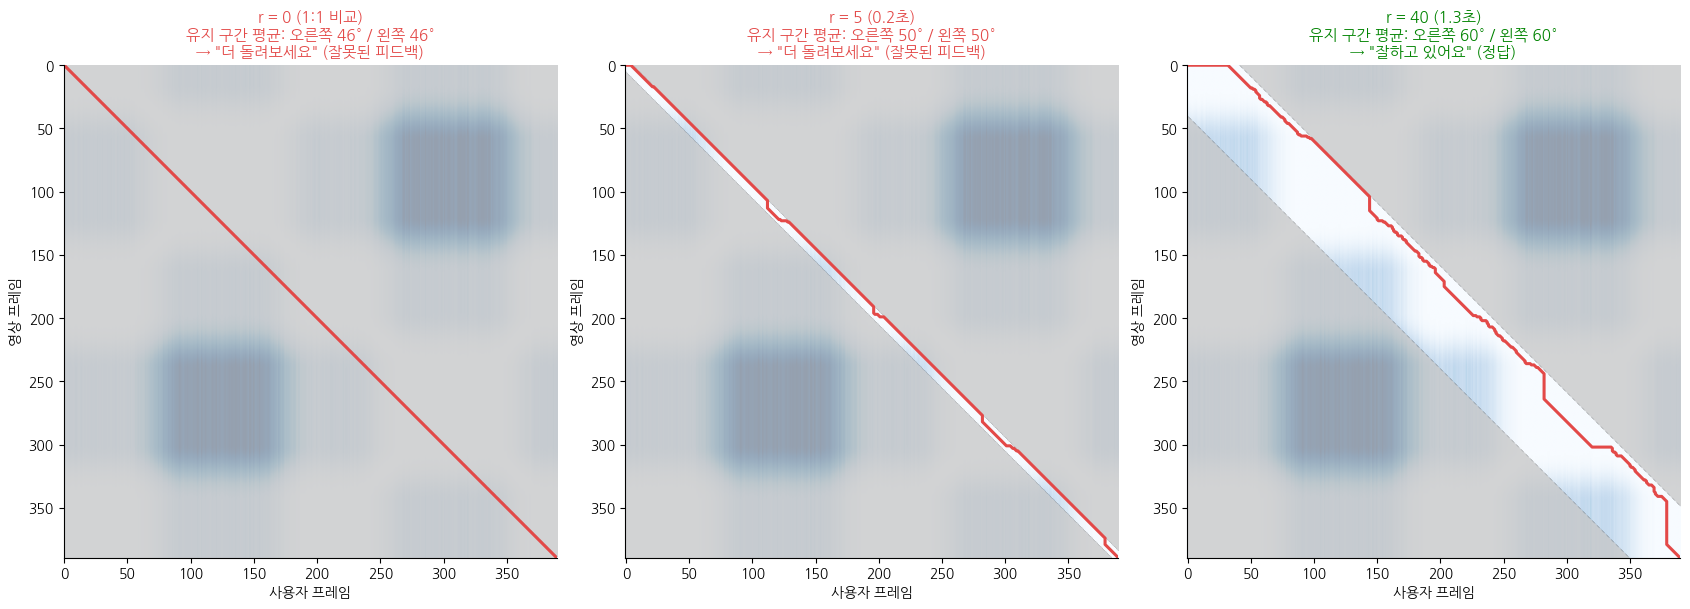

saved: fig14_band_narrow
좁은 밴드: [(0, {'오른쪽': (45.783633662992344, True), '왼쪽': (46.02531199451869, True)}), (5, {'오른쪽': (50.28060856463104, True), '왼쪽': (50.40519652455918, True)}), (40, {'오른쪽': (59.89600688172198, False), '왼쪽': (60.04060667437806, False)})]


In [21]:
rng2 = np.random.default_rng(5)
USR_LATE = neck_rotation(TARGET, TARGET, 1.0, lag=1.1, noise=NOISE_DEG, rng=rng2)   # 양쪽 다 잘했지만 1.1초 늦음
LC = (REF[:, None] - USR_LATE[None, :]) ** 2
fig, axs = plt.subplots(1, 3, figsize=(17, 6))
NARROW_B = []
for ax, r in zip(axs, [0, 5, 40]):
    D, _ = dtw_table(list(REF), list(USR_LATE), r)
    pth = backtrack(D)
    fb = feedback([(i - 1, j - 1) for i, j in pth], USR_LATE)
    NARROW_B.append((r, fb))
    ax.imshow(LC, cmap="Blues", origin="upper", vmin=0, vmax=np.percentile(LC, 99))
    ii, jj = np.indices(LC.shape)
    ax.imshow(np.where(np.abs(ii - jj) > r, 1, np.nan), cmap="Greys", vmin=0, vmax=3, origin="upper", alpha=0.75)
    ax.plot([j - 1 for i, j in pth], [i - 1 for i, j in pth], color=COL_HL, lw=2.2)
    good = not any(b for _, b in fb.values())
    txt = " / ".join(f"{s} {m:.0f}°" for s, (m, _) in fb.items())
    nm = "r = 0 (1:1 비교)" if r == 0 else f"r = {r} ({r/FPS:.1f}초)"
    ax.set_title(f"{nm}\n유지 구간 평균: {txt}\n→ " + ("\"잘하고 있어요\" (정답)" if good else "\"더 돌려보세요\" (잘못된 피드백)"),
                 fontsize=11, color="#008300" if good else COL_HL)
    ax.set_xlabel("사용자 프레임"); ax.set_ylabel("영상 프레임")
fig.tight_layout()
save(fig, "fig14_band_narrow")
print("좁은 밴드:", NARROW_B)

### [20] 그림 15 — 한계: DTW 거리는 '속도 차이'를 지운다

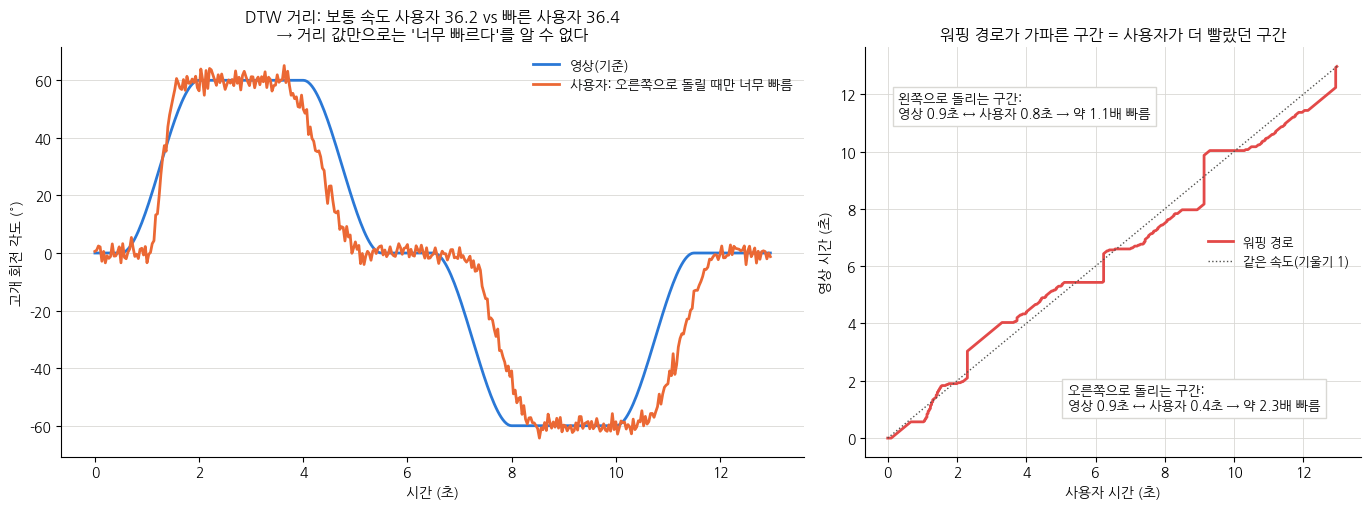

saved: fig15_speed_limit
속도 한계: 보통 36.22, 빠름 36.43, 구간 속도비 {'오른쪽': (28, np.int64(12), np.float64(2.3333333333333335)), '왼쪽': (28, np.int64(25), np.float64(1.12))}


In [22]:
rng3 = np.random.default_rng(9)
USR_OK = neck_rotation(TARGET, TARGET, lag=0.5, noise=NOISE_DEG, rng=rng3)
USR_FAST = neck_rotation(TARGET, TARGET, lag=0.5, up_r=0.6, noise=NOISE_DEG, rng=rng3)   # 오른쪽으로 돌릴 때만 2.5배 빠르게
d_ok, d_fast = dtw(list(REF), list(USR_OK), R_GOOD), dtw(list(REF), list(USR_FAST), R_GOOD)

def phase_speed(usr, side):
    """영상에서 고개를 '돌리는' 구간(6°→54°)과 짝지어진 사용자 프레임 수로 속도 비율을 잰다"""
    D, _ = dtw_table(list(REF), list(usr), R_GOOD)
    pth = np.array(backtrack(D)) - 1
    sign = 1 if side == "오른쪽" else -1
    peak = np.argmax(sign * REF)
    rise = [i for i in range(peak) if 6 <= sign * REF[i] <= 54 and (i == 0 or sign * REF[i] >= sign * REF[i - 1])]
    js = pth[np.isin(pth[:, 0], rise), 1]
    return len(rise), js.max() - js.min() + 1, pth

SPEED = {}
for side in ["오른쪽", "왼쪽"]:
    n_ref, n_usr, pth_f = phase_speed(USR_FAST, side)
    SPEED[side] = (n_ref, n_usr, n_ref / n_usr)
fig, axs = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.5, 1]})
axs[0].plot(t, REF, color=COL_A, lw=2, label="영상(기준)")
axs[0].plot(t, USR_FAST, color=COL_B, lw=2, label="사용자: 오른쪽으로 돌릴 때만 너무 빠름")
axs[0].set_xlabel("시간 (초)"); axs[0].set_ylabel("고개 회전 각도 (°)")
axs[0].set_title(f"DTW 거리: 보통 속도 사용자 {d_ok:.1f} vs 빠른 사용자 {d_fast:.1f}\n→ 거리 값만으로는 '너무 빠르다'를 알 수 없다", fontsize=11.5)
axs[0].legend(frameon=False, fontsize=9.5); axs[0].grid(axis="y", color=COL_GRID, lw=0.6)
axs[1].plot(pth_f[:, 1] / FPS, pth_f[:, 0] / FPS, color=COL_HL, lw=2, label="워핑 경로")
axs[1].plot([0, NREF / FPS], [0, NREF / FPS], ":", color=COL_TXT2, lw=1, label="같은 속도(기울기 1)")
for side, (nr, nu, rt) in SPEED.items():
    sign = 1 if side == "오른쪽" else -1
    peak = np.argmax(sign * REF) / FPS
    xy = (5.2, 1.0) if side == "오른쪽" else (0.3, 11.2)
    axs[1].text(*xy, f"{side}으로 돌리는 구간:\n영상 {nr/FPS:.1f}초 ↔ 사용자 {nu/FPS:.1f}초 → 약 {rt:.1f}배 빠름", fontsize=9.5,
                bbox=dict(fc="white", ec=COL_GRID))
axs[1].set_xlabel("사용자 시간 (초)"); axs[1].set_ylabel("영상 시간 (초)")
axs[1].set_title("워핑 경로가 가파른 구간 = 사용자가 더 빨랐던 구간", fontsize=11.5)
axs[1].legend(frameon=False, fontsize=9, loc="center right"); axs[1].grid(color=COL_GRID, lw=0.6)
fig.tight_layout()
save(fig, "fig15_speed_limit")
print(f"속도 한계: 보통 {d_ok:.2f}, 빠름 {d_fast:.2f}, 구간 속도비 {SPEED}")

### 결과 내려받기 (Colab 전용)
`figs` 폴더를 압축해서 내 컴퓨터로 내려받습니다.

In [23]:
import shutil, sys
shutil.make_archive("figs", "zip", "figs")      # figs.zip 만들기
if "google.colab" in sys.modules:
    from google.colab import files
    files.download("figs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>